This notebook implements an end-to-end customer analytics and **predictive Customer Lifetime Value (CLV)** pipeline for an **e-commerce retail** dataset. The goal is to move beyond total revenue aggregates and analyze customer distribution, behavioral patterns, churn signals, and predictive future value.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import lightgbm as lgb
import xgboost as xgb

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

## Data Loading & Initial Inspection

In [3]:
df = pd.read_csv('/kaggle/input/datasets/miadul/e-commerce-sales-transactions-dataset/ecommerce_sales_34500.csv')

print("Dataset Shape:", df.shape)
display(df.head())
display(df.info())

Dataset Shape: (34500, 17)


,order_id,customer_id,product_id,category,price,discount,quantity,payment_method,order_date,delivery_time_days,region,returned,total_amount,shipping_cost,profit_margin,customer_age,customer_gender
0,O100000,C17270,P234890,Home,164.08,0.15,1,Credit Card,2023-12-23,4,West,No,139.47,7.88,31.17,60,Female
1,O100001,C17603,P228204,Grocery,24.73,0.00,1,Credit Card,2025-04-03,6,South,No,24.73,4.60,-2.62,37,Male
2,O100002,C10860,P213892,Electronics,175.58,0.05,1,Credit Card,2024-10-08,4,North,No,166.80,6.58,13.44,34,Male
3,O100003,C15390,P208689,Electronics,63.67,0.00,1,UPI,2024-09-14,6,South,No,63.67,5.50,2.14,21,Female
4,O100004,C15226,P228063,Home,16.33,0.15,1,COD,2024-12-21,6,East,No,13.88,2.74,1.15,39,Male


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34500 entries, 0 to 34499
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   order_id            34500 non-null  object 
 1   customer_id         34500 non-null  object 
 2   product_id          34500 non-null  object 
 3   category            34500 non-null  object 
 4   price               34500 non-null  float64
 5   discount            34500 non-null  float64
 6   quantity            34500 non-null  int64  
 7   payment_method      34500 non-null  object 
 8   order_date          34500 non-null  object 
 9   delivery_time_days  34500 non-null  int64  
 10  region              34500 non-null  object 
 11  returned            34500 non-null  object 
 12  total_amount        34500 non-null  float64
 13  shipping_cost       34500 non-null  float64
 14  profit_margin       34500 non-null  float64
 15  customer_age        34500 non-null  int64  
 16  cust

None

## Data Dictionary

To understand the raw features before cleaning and feature engineering, we construct a comprehensive data dictionary for every column retained from the source dataset.

In [4]:
data_dict = pd.DataFrame({
    'Column Name': [
        'order_id', 'customer_id', 'product_id', 'category', 'price', 
        'discount', 'quantity', 'payment_method', 'order_date', 
        'delivery_time', 'region', 'returned', 'total_amount', 
        'shipping_fee', 'profit_margin', 'customer_age', 'customer_gender'
    ],
    'Data Type': [
        'Object', 'Object', 'Object', 'Object', 'Float', 
        'Float', 'Integer', 'Object', 'Object (Datetime)', 
        'Integer', 'Object', 'Object', 'Float', 
        'Float', 'Float', 'Integer', 'Object'
    ],
    'Description': [
        'Unique identifier for each transaction order',
        'Unique identifier for each customer',
        'Unique identifier for each product',
        'Product category classification',
        'Unit price of the product',
        'Discount rate applied to the item',
        'Number of units purchased in the transaction',
        'Payment method used by the customer',
        'Date when the order was placed',
        'Days taken to deliver the order',
        'Geographical region of the transaction',
        'Indicator whether the order was returned',
        'Total final amount paid for the transaction',
        'Shipping fee charged for the order',
        'Profit margin generated on the transaction',
        'Age of the customer',
        'Gender of the customer'
    ]
})

display(data_dict)

,Column Name,Data Type,Description
0,order_id,Object,Unique identifier for each transaction order
1,customer_id,Object,Unique identifier for each customer
2,product_id,Object,Unique identifier for each product
3,category,Object,Product category classification
4,price,Float,Unit price of the product
5,discount,Float,Discount rate applied to the item
6,quantity,Integer,Number of units purchased in the transaction
7,payment_method,Object,Payment method used by the customer
8,order_date,Object (Datetime),Date when the order was placed
9,delivery_time,Integer,Days taken to deliver the order


## Data Cleaning & Preprocessing

In [5]:
print("Missing values before cleaning:")
display(df.isnull().sum())

df = df.drop_duplicates()
df['order_date'] = pd.to_datetime(df['order_date'])

df['total_amount'] = pd.to_numeric(df['total_amount'], errors='coerce')
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df['quantity'] = pd.to_numeric(df['quantity'], errors='coerce')

df = df.dropna(subset=['order_id', 'customer_id', 'order_date', 'total_amount'])

print("Cleaned dataset shape:", df.shape)

Missing values before cleaning:


order_id              0
customer_id           0
product_id            0
category              0
price                 0
discount              0
quantity              0
payment_method        0
order_date            0
delivery_time_days    0
region                0
returned              0
total_amount          0
shipping_cost         0
profit_margin         0
customer_age          0
customer_gender       0
dtype: int64

Cleaned dataset shape: (34500, 17)


## Exploratory Data Analysis (EDA)

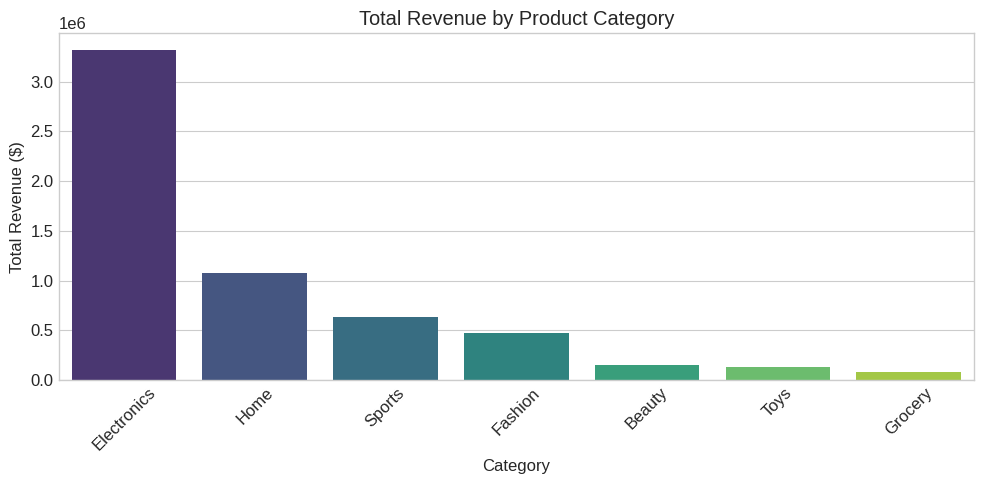

In [6]:
plt.figure(figsize=(10, 5))
category_rev = df.groupby('category')['total_amount'].sum().sort_values(ascending=False)
sns.barplot(x=category_rev.index, y=category_rev.values, palette='viridis')
plt.title('Total Revenue by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Revenue ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

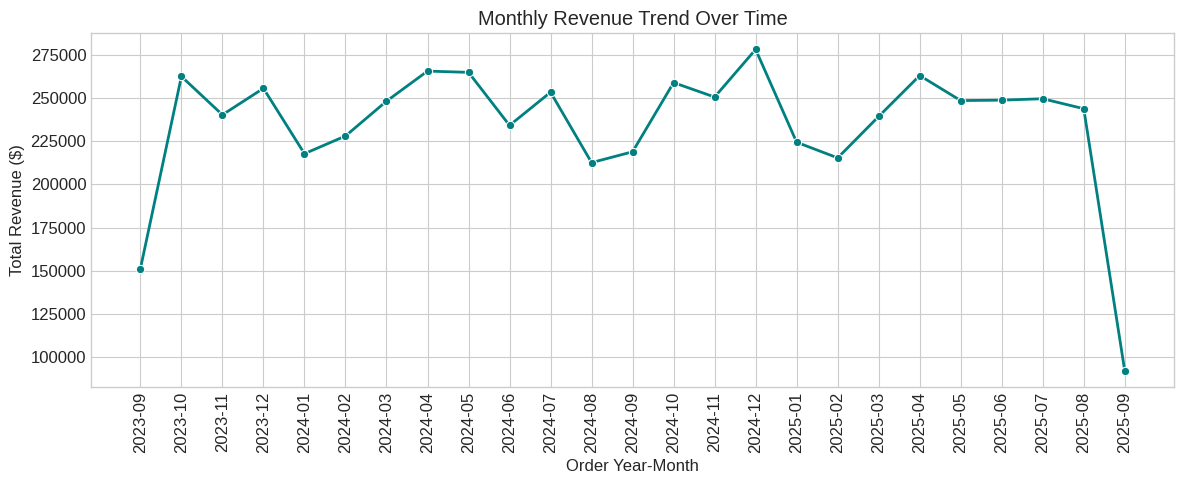

In [7]:
df['order_year_month'] = df['order_date'].dt.to_period('M')
monthly_rev = df.groupby('order_year_month')['total_amount'].sum().reset_index()
monthly_rev['order_year_month'] = monthly_rev['order_year_month'].astype(str)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_rev, x='order_year_month', y='total_amount', marker='o', color='teal', linewidth=2)
plt.title('Monthly Revenue Trend Over Time')
plt.xlabel('Order Year-Month')
plt.ylabel('Total Revenue ($)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

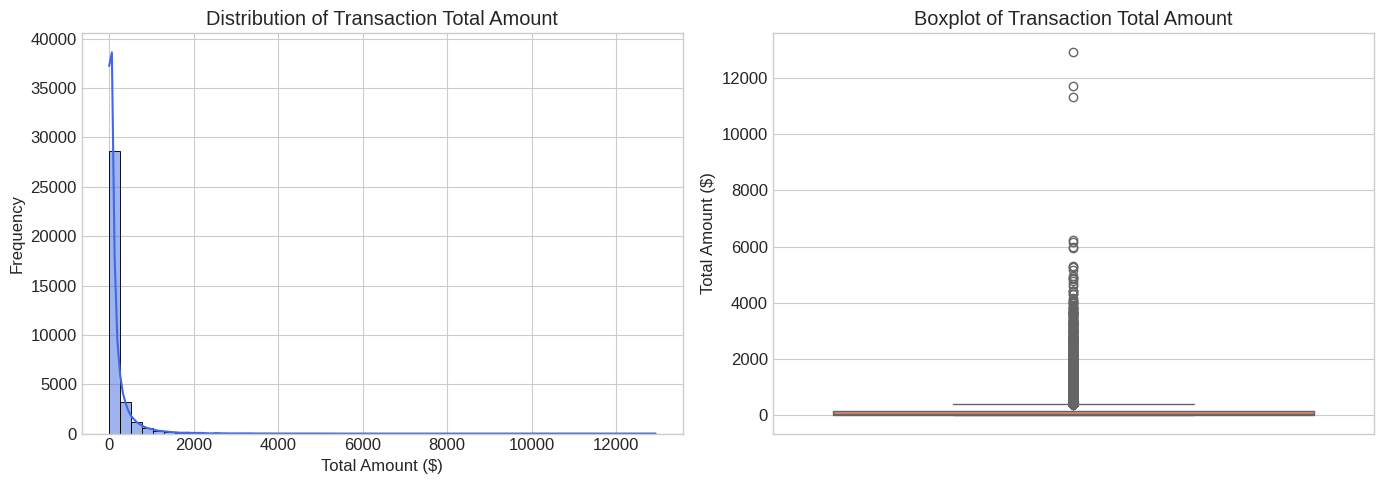

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['total_amount'], bins=50, kde=True, ax=axes[0], color='royalblue')
axes[0].set_title('Distribution of Transaction Total Amount')
axes[0].set_xlabel('Total Amount ($)')
axes[0].set_ylabel('Frequency')

sns.boxplot(y=df['total_amount'], ax=axes[1], color='coral')
axes[1].set_title('Boxplot of Transaction Total Amount')
axes[1].set_ylabel('Total Amount ($)')

plt.tight_layout()
plt.show()

## Customer Behaviour Feature Engineering

We aggregate transaction-level data to the customer level to construct behavioral features, including Recency, Frequency, Monetary value, Average Order Value (AOV), Customer Tenure, Product Diversity, and Total Quantity purchased.

In [9]:
analysis_date = df['order_date'].max() + dt.timedelta(days=1)

customer_rfm = df.groupby('customer_id').agg(
    recency=('order_date', lambda x: (analysis_date - x.max()).days),
    frequency=('order_id', 'nunique'),
    monetary=('total_amount', 'sum'),
    first_purchase=('order_date', 'min'),
    last_purchase=('order_date', 'max'),
    product_diversity=('product_id', 'nunique'),
    total_quantity=('quantity', 'sum')
).reset_index()

customer_rfm['tenure'] = (customer_rfm['last_purchase'] - customer_rfm['first_purchase']).dt.days
customer_rfm['aov'] = customer_rfm['monetary'] / customer_rfm['frequency']
customer_rfm['purchase_interval'] = customer_rfm['tenure'] / customer_rfm['frequency'].replace(1, 1)

customer_rfm = customer_rfm.drop(columns=['first_purchase', 'last_purchase'])

display(customer_rfm.head())
print("Customer RFM shape:", customer_rfm.shape)

,customer_id,recency,frequency,monetary,product_diversity,total_quantity,tenure,aov,purchase_interval
0,C10000,5,2,210.58,2,2,386,105.290000,193.0
1,C10001,194,5,3246.02,5,12,407,649.204000,81.4
2,C10002,401,5,216.85,5,6,266,43.370000,53.2
3,C10003,72,3,154.30,3,3,378,51.433333,126.0
4,C10004,600,3,716.99,3,5,54,238.996667,18.0


Customer RFM shape: (7903, 9)


## RFM Scoring & Segmentation

We score customers from 1 to 5 using quantile bins for Recency, Frequency, and Monetary metrics, and combine them into actionable behavioral segments.

In [10]:
r_labels = range(5, 0, -1)
f_labels = range(1, 6)
m_labels = range(1, 6)

customer_rfm['r_score'] = pd.qcut(customer_rfm['recency'], q=5, labels=r_labels, duplicates='drop')
customer_rfm['f_score'] = pd.qcut(customer_rfm['frequency'].rank(method='first'), q=5, labels=f_labels)
customer_rfm['m_score'] = pd.qcut(customer_rfm['monetary'], q=5, labels=m_labels)

customer_rfm['r_score'] = customer_rfm['r_score'].astype(int)
customer_rfm['f_score'] = customer_rfm['f_score'].astype(int)
customer_rfm['m_score'] = customer_rfm['m_score'].astype(int)

customer_rfm['rfm_score'] = customer_rfm['r_score'].astype(str) + customer_rfm['f_score'].astype(str) + customer_rfm['m_score'].astype(str)

def segment_customer(row):
    if row['r_score'] >= 4 and row['f_score'] >= 4 and row['m_score'] >= 4:
        return 'Champions'
    elif row['r_score'] >= 3 and row['f_score'] >= 3 and row['m_score'] >= 3:
        return 'Loyal Customers'
    elif row['r_score'] >= 4 and row['f_score'] <= 2:
        return 'New Customers'
    elif row['r_score'] <= 2 and row['f_score'] >= 3:
        return 'At Risk'
    elif row['r_score'] <= 2 and row['f_score'] <= 2:
        return 'Hibernating'
    else:
        return 'Potential Loyalists'

customer_rfm['segment'] = customer_rfm.apply(segment_customer, axis=1)

display(customer_rfm['segment'].value_counts())

segment
Hibernating            1845
Loyal Customers        1570
At Risk                1299
Potential Loyalists    1270
Champions              1126
New Customers           793
Name: count, dtype: int64

## RFM Visualization

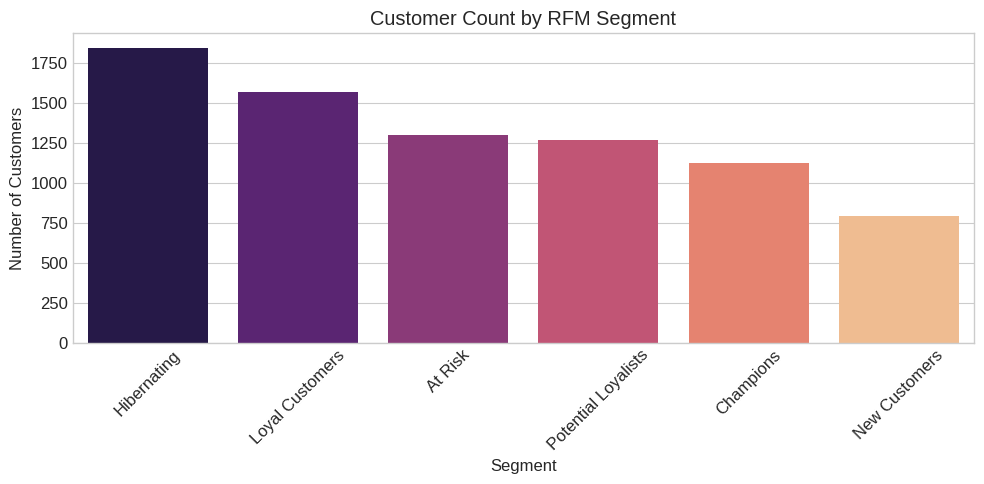

In [11]:
plt.figure(figsize=(10, 5))
segment_counts = customer_rfm['segment'].value_counts()
sns.barplot(x=segment_counts.index, y=segment_counts.values, palette='magma')
plt.title('Customer Count by RFM Segment')
plt.xlabel('Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

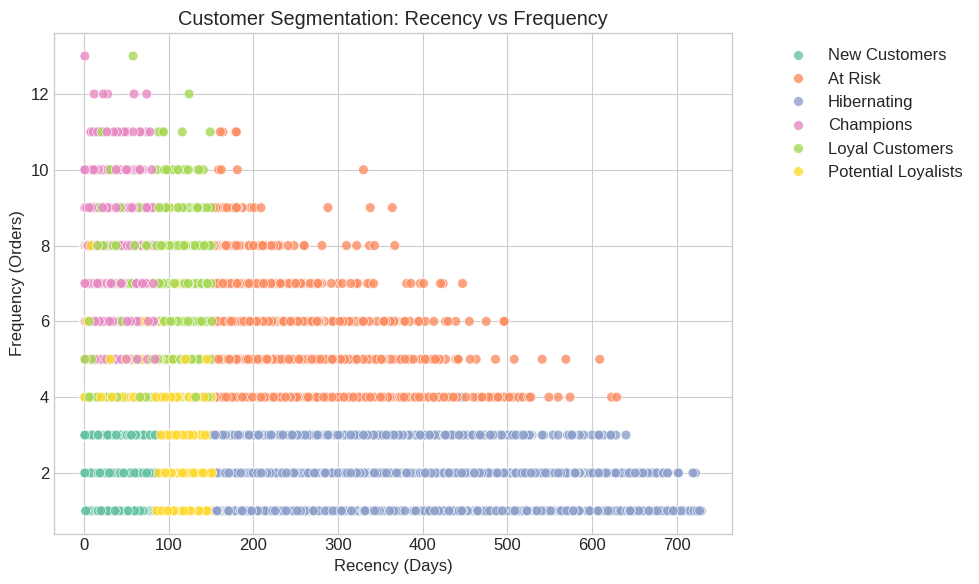

In [12]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=customer_rfm, 
    x='recency', 
    y='frequency', 
    hue='segment', 
    palette='Set2', 
    alpha=0.8, 
    s=50
)
plt.title('Customer Segmentation: Recency vs Frequency')
plt.xlabel('Recency (Days)')
plt.ylabel('Frequency (Orders)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Heuristic Customer Lifetime Value (CLV) Calculation

We compute a baseline heuristic Customer Lifetime Value using the classical formula incorporating Average Order Value, Purchase Frequency, Expected Customer Lifespan, and Profit Margin.

In [13]:
avg_profit_margin = (df['profit_margin'] / df['total_amount']).mean()
if pd.isna(avg_profit_margin) or avg_profit_margin <= 0:
    avg_profit_margin = 0.20

customer_rfm['avg_lifespan_years'] = 3.0
customer_rfm['annual_frequency'] = customer_rfm['frequency'] / np.maximum(customer_rfm['tenure'] / 365.0, 1.0)

customer_rfm['heuristic_clv'] = (
    customer_rfm['aov'] * 
    customer_rfm['annual_frequency'] * 
    customer_rfm['avg_lifespan_years'] * 
    avg_profit_margin
)

display(customer_rfm[['customer_id', 'monetary', 'frequency', 'aov', 'heuristic_clv']].head())

,customer_id,monetary,frequency,aov,heuristic_clv
0,C10000,210.58,2,105.290000,65.144226
1,C10001,3246.02,5,649.204000,952.363839
2,C10002,216.85,5,43.370000,70.943511
3,C10003,154.30,3,51.433333,48.743896
4,C10004,716.99,3,238.996667,234.566695


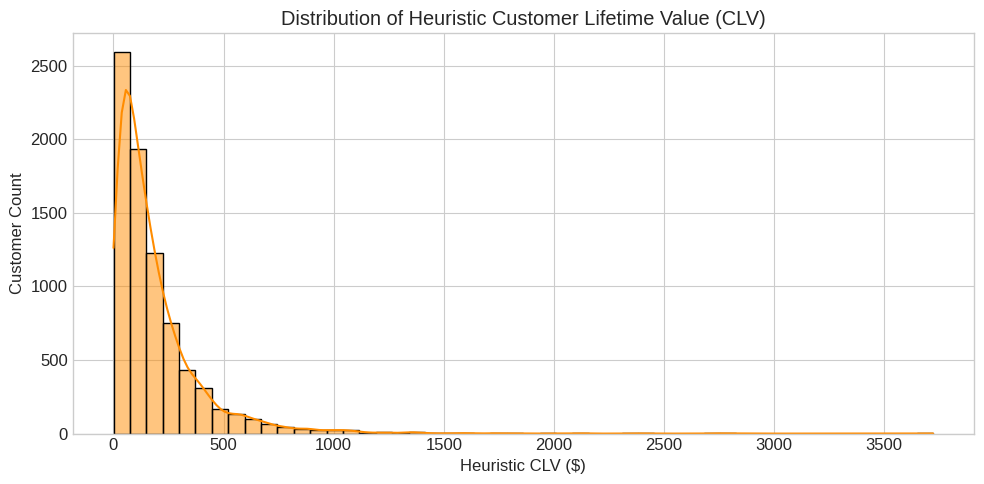

In [14]:
plt.figure(figsize=(10, 5))
sns.histplot(customer_rfm['heuristic_clv'], bins=50, kde=True, color='darkorange')
plt.title('Distribution of Heuristic Customer Lifetime Value (CLV)')
plt.xlabel('Heuristic CLV ($)')
plt.ylabel('Customer Count')
plt.tight_layout()
plt.show()

## Predictive CLV: Temporal Train/Test Split Setup

To build a rigorous supervised regression model for predictive CLV, we establish a historical observation window and a future prediction window. We use transactions prior to the cutoff date to extract features, and transactions after the cutoff date as our target variable (future revenue).

In [18]:
max_date = df['order_date'].max()
cutoff_date = max_date - dt.timedelta(days=365)

print(f"Overall Date Range: {df['order_date'].min().date()} to {max_date.date()}")
print(f"Observation Window Cutoff Date: {cutoff_date.date()}")

obs_df = df[df['order_date'] <= cutoff_date]
pred_df = df[df['order_date'] > cutoff_date]

print(f"Observation transactions shape: {obs_df.shape}")
print(f"Prediction transactions shape: {pred_df.shape}")

Overall Date Range: 2023-09-12 to 2025-09-11
Observation Window Cutoff Date: 2024-09-11
Observation transactions shape: (17041, 18)
Prediction transactions shape: (17459, 18)


## Feature Engineering from Observation Window

In [24]:
print("Available columns in dataframe:", list(df.columns))

obs_analysis_date = cutoff_date + dt.timedelta(days=1)

features_list = []
for cust_id, group in obs_df.groupby('customer_id'):
    recency = (obs_analysis_date - group['order_date'].max()).days
    frequency = group['order_id'].nunique()
    monetary = group['total_amount'].sum()
    tenure = (group['order_date'].max() - group['order_date'].min()).days
    product_diversity = group['product_id'].nunique()
    total_quantity = group['quantity'].sum()
    
    avg_discount = group['discount'].mean() if 'discount' in group.columns else 0.0
    
    delivery_col = next((col for col in ['delivery_time', 'delivery_t'] if col in group.columns), None)
    avg_delivery_time = group[delivery_col].mean() if delivery_col else 0.0
    
    return_col = next((col for col in ['returned', 'return'] if col in group.columns), None)
    return_rate = (group[return_col] == 'Yes').mean() if return_col else 0.0
    
    features_list.append({
        'customer_id': cust_id,
        'recency': recency,
        'frequency': frequency,
        'monetary': monetary,
        'tenure': tenure,
        'product_diversity': product_diversity,
        'total_quantity': total_quantity,
        'avg_discount': avg_discount,
        'avg_delivery_time': avg_delivery_time,
        'return_rate': return_rate
    })

X_features = pd.DataFrame(features_list)
X_features['aov'] = X_features['monetary'] / X_features['frequency']
X_features['purchase_interval'] = X_features['tenure'] / X_features['frequency'].replace(1, 1)

y_target = pred_df.groupby('customer_id')['total_amount'].sum().reset_index()
y_target.columns = ['customer_id', 'future_monetary']

modeling_df = pd.merge(X_features, y_target, on='customer_id', how='left')
modeling_df['future_monetary'] = modeling_df['future_monetary'].fillna(0)

display(modeling_df.head())
print("Modeling dataset shape:", modeling_df.shape)

Available columns in dataframe: ['order_id', 'customer_id', 'product_id', 'category', 'price', 'discount', 'quantity', 'payment_method', 'order_date', 'delivery_time_days', 'region', 'returned', 'total_amount', 'shipping_cost', 'profit_margin', 'customer_age', 'customer_gender', 'order_year_month']


,customer_id,recency,frequency,monetary,tenure,product_diversity,total_quantity,avg_discount,avg_delivery_time,return_rate,aov,purchase_interval,future_monetary
0,C10000,26,1,33.12,0,1,1,0.15,0.0,0.0,33.120000,0.000000,177.46
1,C10001,24,3,1445.30,212,3,8,0.00,0.0,0.0,481.766667,70.666667,1800.72
2,C10002,36,5,216.85,266,5,6,0.13,0.0,0.0,43.370000,53.200000,0.00
3,C10003,85,1,115.13,0,1,1,0.00,0.0,0.0,115.130000,0.000000,39.17
4,C10004,235,3,716.99,54,3,5,0.00,0.0,0.0,238.996667,18.000000,0.00


Modeling dataset shape: (7029, 13)


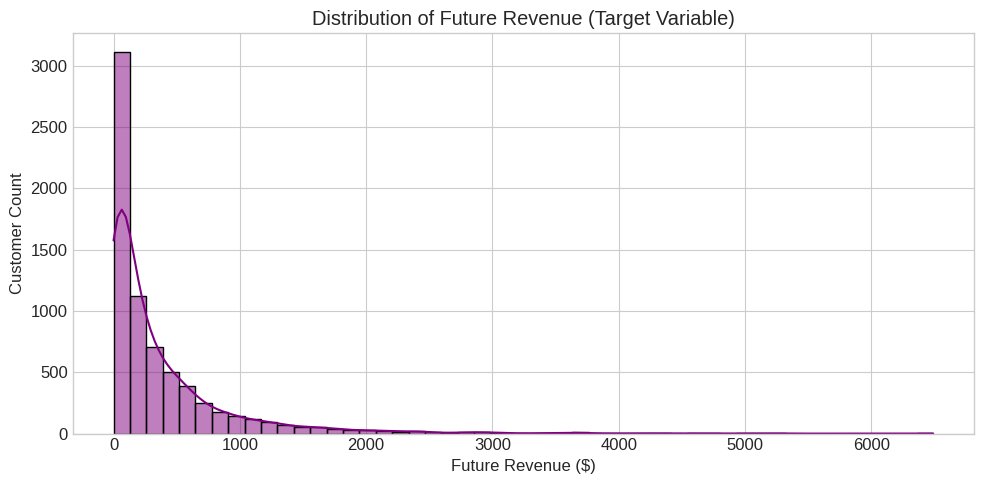

In [25]:
plt.figure(figsize=(10, 5))
sns.histplot(modeling_df['future_monetary'], bins=50, kde=True, color='purple')
plt.title('Distribution of Future Revenue (Target Variable)')
plt.xlabel('Future Revenue ($)')
plt.ylabel('Customer Count')
plt.tight_layout()
plt.show()

## Model Selection & Justification

To predict future customer lifetime value (CLV) over the next 365 days, we frame the problem as a supervised regression task.
Random Forest Regressor: Robust non-linear ensemble model that handles multicollinearity well and is resistant to overfitting.

    Gradient Boosting Regressor: Sequential ensemble technique that iteratively minimizes residual errors, capturing complex feature interactions.

    LightGBM Regressor: Highly efficient gradient boosting framework optimized for speed and performance on tabular behavioral datasets.

    XGBoost Regressor: Industry-standard regularized gradient boosting model known for high predictive accuracy.

## Feature Matrix & Train/Test Split

In [26]:
feature_cols = [
    'recency', 'frequency', 'monetary', 'tenure', 
    'product_diversity', 'total_quantity', 'avg_discount', 
    'avg_delivery_time', 'return_rate', 'aov', 'purchase_interval'
]

X = modeling_df[feature_cols].fillna(0)
y = modeling_df['future_monetary']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Training set shape: (5623, 11)
Test set shape: (1406, 11)


## Model Training & Evaluation Function
We define an evaluation helper function to compute MAE, RMSE, R-squared ($R^2$), and MAPE across all models.

In [29]:
def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    
    non_zero_mask = y_true > 0
    mape = np.mean(np.abs((y_true[non_zero_mask] - y_pred[non_zero_mask]) / y_true[non_zero_mask])) * 100 if non_zero_mask.sum() > 0 else 0.0
    
    print(f"--- {model_name} Performance ---")
    print(f"MAE:  ${mae:.2f}")
    print(f"RMSE: ${rmse:.2f}")
    print(f"R²:   {r2:.4f}")
    print(f"MAPE: {mape:.2f}%\n")
    
    return {'Model': model_name, 'MAE': mae, 'RMSE': rmse, 'R2': r2, 'MAPE': mape}

results = []

In [30]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
results.append(evaluate_model(y_test, rf_pred, 'Random Forest'))

gb_model = GradientBoostingRegressor(n_estimators=100, random_state=42)
gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)
results.append(evaluate_model(y_test, gb_pred, 'Gradient Boosting'))

lgb_model = lgb.LGBMRegressor(n_estimators=100, random_state=42, verbose=-1)
lgb_model.fit(X_train, y_train)
lgb_pred = lgb_model.predict(X_test)
results.append(evaluate_model(y_test, lgb_pred, 'LightGBM'))

xgb_model = xgb.XGBRegressor(n_estimators=100, random_state=42, n_jobs=-1)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
results.append(evaluate_model(y_test, xgb_pred, 'XGBoost'))

results_df = pd.DataFrame(results)
display(results_df)

--- Random Forest Performance ---
MAE:  $366.85
RMSE: $542.84
R²:   -0.1315
MAPE: 573.26%

--- Gradient Boosting Performance ---
MAE:  $335.03
RMSE: $514.51
R²:   -0.0165
MAPE: 498.17%

--- LightGBM Performance ---
MAE:  $350.66
RMSE: $531.79
R²:   -0.0859
MAPE: 525.92%

--- XGBoost Performance ---
MAE:  $383.22
RMSE: $577.17
R²:   -0.2791
MAPE: 554.40%



,Model,MAE,RMSE,R2,MAPE
0,Random Forest,366.853819,542.843793,-0.131492,573.256814
1,Gradient Boosting,335.026643,514.512339,-0.016467,498.173293
2,LightGBM,350.658503,531.790691,-0.085884,525.921401
3,XGBoost,383.215349,577.173320,-0.279129,554.400892


## Model Comparison Visualizations

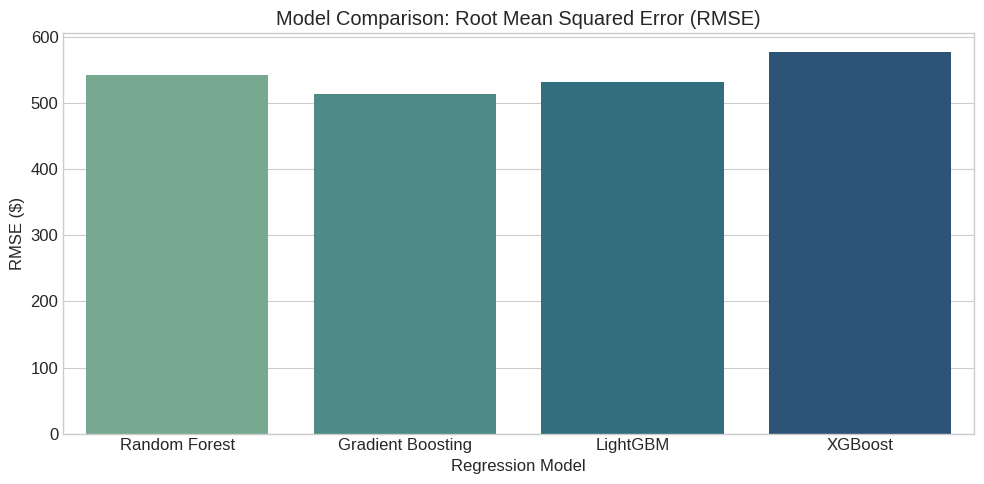

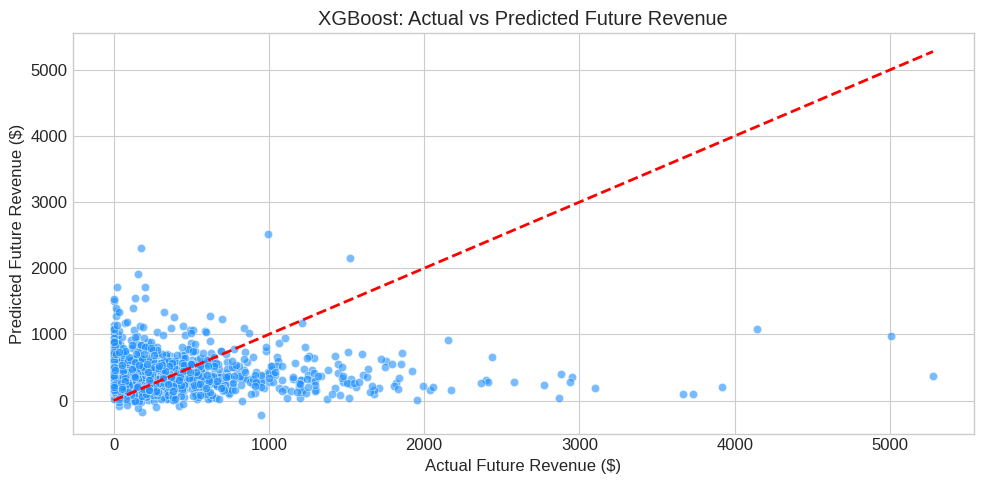

In [32]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x='Model', y='RMSE', palette='crest')
plt.title('Model Comparison: Root Mean Squared Error (RMSE)')
plt.ylabel('RMSE ($)')
plt.xlabel('Regression Model')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.scatterplot(x=y_test, y=xgb_pred, alpha=0.6, color='dodgerblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r', linewidth=2)
plt.title('XGBoost: Actual vs Predicted Future Revenue')
plt.xlabel('Actual Future Revenue ($)')
plt.ylabel('Predicted Future Revenue ($)')
plt.tight_layout()
plt.show()

## Feature Importance Analysis

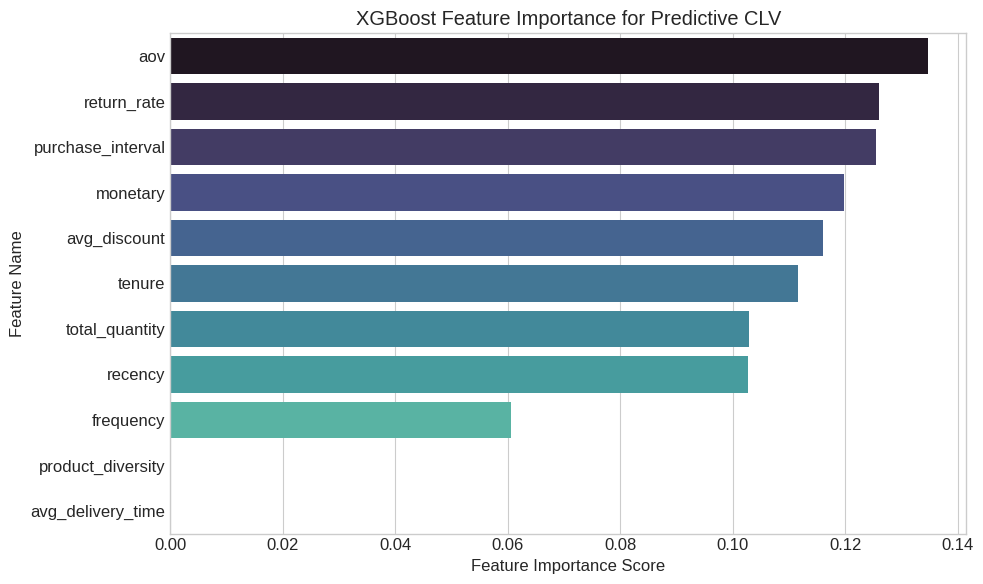

In [33]:
importances = xgb_model.feature_importances_
feature_imp_df = pd.DataFrame({'Feature': feature_cols, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_imp_df, x='Importance', y='Feature', palette='mako')
plt.title('XGBoost Feature Importance for Predictive CLV')
plt.xlabel('Feature Importance Score')
plt.ylabel('Feature Name')
plt.tight_layout()
plt.show()

## High-Value Customer Tiering

A continuous CLV prediction is not directly actionable for campaign planning. We convert our predicted 365-day CLV values into defensible value tiers using percentile thresholds to separate high-impact customers from low-engagement accounts.

In [35]:
modeling_df['predicted_clv'] = xgb_model.predict(scaler.transform(modeling_df[feature_cols]))

q85 = modeling_df['predicted_clv'].quantile(0.85)
q50 = modeling_df['predicted_clv'].quantile(0.50)
q20 = modeling_df['predicted_clv'].quantile(0.20)

def assign_clv_tier(val):
    if val >= q85:
        return 'Platinum (Top 15%)'
    elif val >= q50:
        return 'Gold (15% - 50%)'
    elif val >= q20:
        return 'Silver (50% - 80%)'
    else:
        return 'Bronze (Bottom 20%)'

modeling_df['clv_tier'] = modeling_df['predicted_clv'].apply(assign_clv_tier)

tier_summary = modeling_df.groupby('clv_tier').agg(
    customer_count=('customer_id', 'count'),
    total_predicted_revenue=('predicted_clv', 'sum'),
    mean_predicted_revenue=('predicted_clv', 'mean')
).reset_index()

display(tier_summary)

,clv_tier,customer_count,total_predicted_revenue,mean_predicted_revenue
0,Bronze (Bottom 20%),97,1.976865e+04,203.800476
1,Gold (15% - 50%),106,5.705346e+04,538.240234
2,Platinum (Top 15%),3481,2.133024e+06,612.761841
3,Silver (50% - 80%),3345,9.368795e+05,280.083557


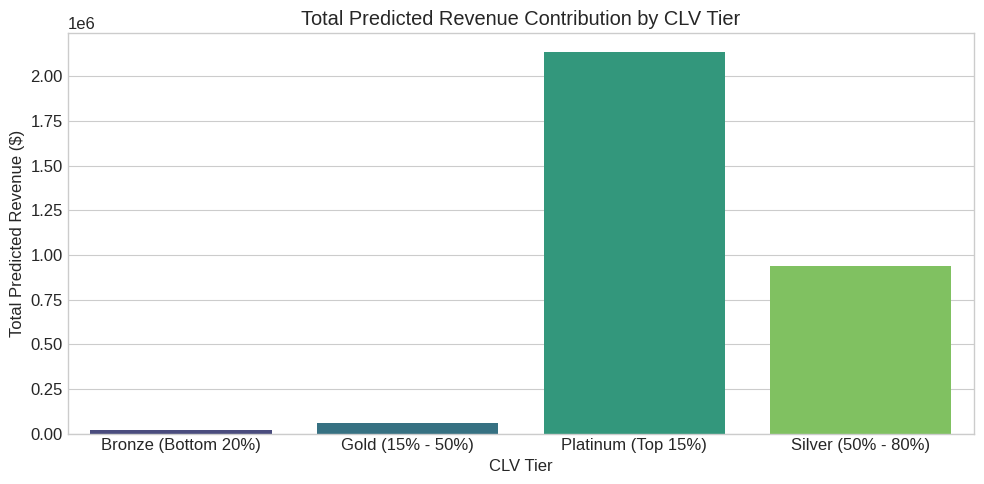

In [36]:
plt.figure(figsize=(10, 5))
sns.barplot(data=tier_summary, x='clv_tier', y='total_predicted_revenue', palette='viridis')
plt.title('Total Predicted Revenue Contribution by CLV Tier')
plt.xlabel('CLV Tier')
plt.ylabel('Total Predicted Revenue ($)')
plt.tight_layout()
plt.show()

## Algorithmic Clustering vs. Rule-Based Segmentation

We compare our heuristic RFM rule-based segments with an unsupervised machine learning approach (K-Means Clustering) built on standardized behavioral features.

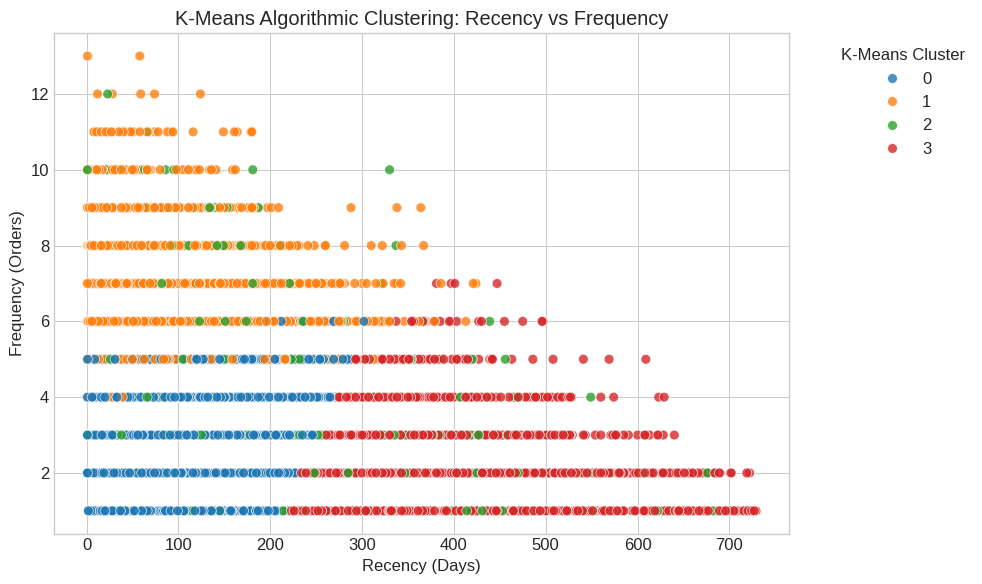

In [37]:
from sklearn.cluster import KMeans

cluster_features = ['recency', 'frequency', 'monetary', 'aov']
X_cluster = customer_rfm[cluster_features].fillna(0)
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
customer_rfm['kmeans_cluster'] = kmeans.fit_predict(X_cluster_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=customer_rfm, 
    x='recency', 
    y='frequency', 
    hue='kmeans_cluster', 
    palette='tab10', 
    alpha=0.8, 
    s=50
)
plt.title('K-Means Algorithmic Clustering: Recency vs Frequency')
plt.xlabel('Recency (Days)')
plt.ylabel('Frequency (Orders)')
plt.legend(title='K-Means Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Error & Model Analysis: Systematic Residual Investigation

To understand where our regression model fails, we analyze residuals systematically across different customer behavioral subsets rather than relying solely on aggregate metrics.

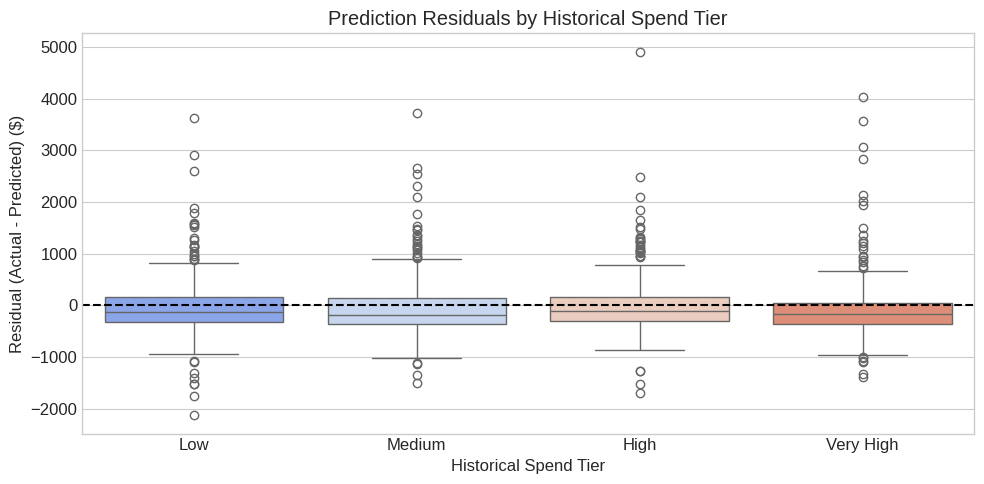

In [38]:
test_results_df = X_test.copy()
test_results_df['actual'] = y_test
test_results_df['predicted'] = xgb_pred
test_results_df['residual'] = test_results_df['actual'] - test_results_df['predicted']

test_results_df['spend_tier'] = pd.qcut(test_results_df['monetary'], q=4, labels=['Low', 'Medium', 'High', 'Very High'])

plt.figure(figsize=(10, 5))
sns.boxplot(data=test_results_df, x='spend_tier', y='residual', palette='coolwarm')
plt.axhline(0, color='black', linestyle='--', linewidth=1.5)
plt.title('Prediction Residuals by Historical Spend Tier')
plt.xlabel('Historical Spend Tier')
plt.ylabel('Residual (Actual - Predicted) ($)')
plt.tight_layout()
plt.show()

# Executive Business Intelligence Dashboard

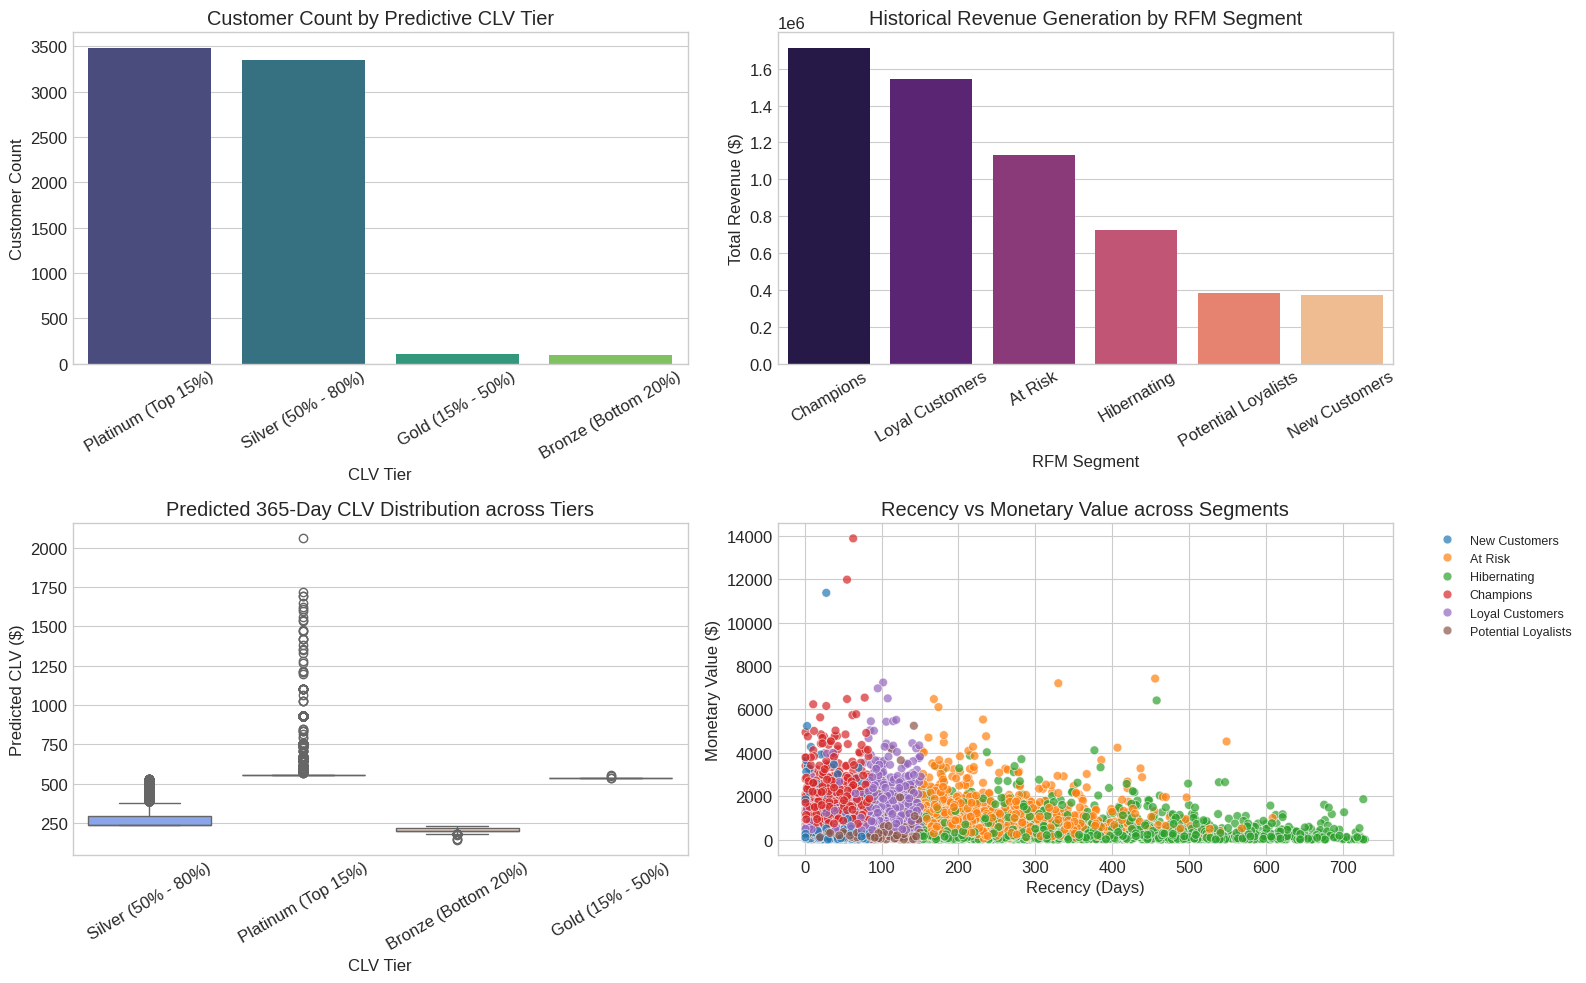

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

tier_counts = modeling_df['clv_tier'].value_counts()
sns.barplot(x=tier_counts.index, y=tier_counts.values, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Customer Count by Predictive CLV Tier')
axes[0, 0].set_xlabel('CLV Tier')
axes[0, 0].set_ylabel('Customer Count')
axes[0, 0].tick_params(axis='x', rotation=30)

seg_rev = customer_rfm.groupby('segment')['monetary'].sum().sort_values(ascending=False)
sns.barplot(x=seg_rev.index, y=seg_rev.values, ax=axes[0, 1], palette='magma')
axes[0, 1].set_title('Historical Revenue Generation by RFM Segment')
axes[0, 1].set_xlabel('RFM Segment')
axes[0, 1].set_ylabel('Total Revenue ($)')
axes[0, 1].tick_params(axis='x', rotation=30)

sns.boxplot(data=modeling_df, x='clv_tier', y='predicted_clv', ax=axes[1, 0], palette='coolwarm')
axes[1, 0].set_title('Predicted 365-Day CLV Distribution across Tiers')
axes[1, 0].set_xlabel('CLV Tier')
axes[1, 0].set_ylabel('Predicted CLV ($)')
axes[1, 0].tick_params(axis='x', rotation=30)

sns.scatterplot(
    data=customer_rfm, 
    x='recency', 
    y='monetary', 
    hue='segment', 
    ax=axes[1, 1], 
    palette='tab10', 
    alpha=0.7, 
    s=40
)
axes[1, 1].set_title('Recency vs Monetary Value across Segments')
axes[1, 1].set_xlabel('Recency (Days)')
axes[1, 1].set_ylabel('Monetary Value ($)')
axes[1, 1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()

## Prioritization Framework Implementation

We implement the business prioritization framework by defining Retention Opportunity as a normalized risk-exposure score (combining recency drift and historical value) and multiplying it by our Predicted CLV.

In [40]:
max_recency = customer_rfm['recency'].max()
customer_rfm['retention_opportunity'] = (customer_rfm['recency'] / max_recency) * customer_rfm['monetary']

merged_prioritization = pd.merge(
    modeling_df[['customer_id', 'predicted_clv', 'clv_tier']], 
    customer_rfm[['customer_id', 'retention_opportunity', 'segment']], 
    on='customer_id'
)

merged_prioritization['priority_score'] = merged_prioritization['predicted_clv'] * merged_prioritization['retention_opportunity']

top_priorities = merged_prioritization.sort_values(by='priority_score', ascending=False).head(10)
display(top_priorities)

,customer_id,predicted_clv,clv_tier,retention_opportunity,segment,priority_score
5787,C16594,1380.097900,Platinum (Top 15%),4030.475391,Hibernating,5.562451e+06
1280,C11450,1209.321655,Platinum (Top 15%),1856.572510,Hibernating,2.245193e+06
6251,C17116,474.667145,Silver (50% - 80%),4644.031605,At Risk,2.204369e+06
7003,C17970,1476.163330,Platinum (Top 15%),1458.177284,At Risk,2.152508e+06
991,C11122,1610.593384,Platinum (Top 15%),1309.621687,Hibernating,2.109268e+06
5253,C15981,1650.783813,Platinum (Top 15%),1268.730988,Hibernating,2.094401e+06
863,C10975,600.779846,Platinum (Top 15%),3263.387654,At Risk,1.960578e+06
5842,C16655,1599.469116,Platinum (Top 15%),1199.946914,Champions,1.919278e+06
5715,C16515,1419.703491,Platinum (Top 15%),1277.649383,Hibernating,1.813883e+06
5111,C15820,1467.626709,Platinum (Top 15%),1196.275926,At Risk,1.755687e+06


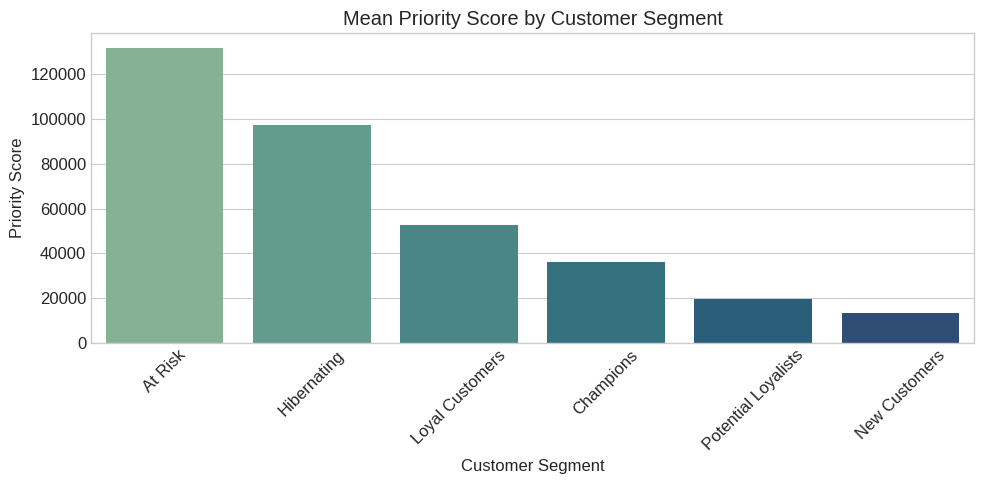

In [41]:
plt.figure(figsize=(10, 5))
top_segment_priority = merged_prioritization.groupby('segment')['priority_score'].mean().sort_values(ascending=False)
sns.barplot(x=top_segment_priority.index, y=top_segment_priority.values, palette='crest')
plt.title('Mean Priority Score by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Priority Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Business Insights & Strategic Recommendations

Based on our end-to-end analytical pipeline, machine learning predictions, and error diagnostics, we present the following actionable strategies for leadership:

### Platinum & Champion Tiers (Top 15% Revenue Generators)

* Specific Action: Provide VIP concierge service, early product access, and exclusive bundling discounts.

* Expected Effect: Protects high-margin core revenue and prevents churn among the most concentrated revenue source.

* Verification Metric: Retention rate and average order frequency in the Platinum tier.

### At-Risk & Drifting High-Value Customers

* Specific Action: Trigger automated re-engagement email sequences with tailored incentives when recency exceeds the normal purchase interval threshold.

* Expected Effect: Recovers exposed revenue from high-value accounts before total dormancy sets in.

* Verification Metric: Reactivation rate within 30 days of trigger deployment.

### New Customers & Single-Purchase Accounts

* Specific Action: Implement onboarding educational workflows and second-purchase cross-sell incentives within 14 days of the initial transaction.

* Expected Effect: Accelerates habit formation and increases transition rates from single-purchase to repeat buyers.

* Verification Metric: 60-day repeat purchase rate